# GNN fixed-architecture results

Reads every `results.json` under `outputs/train/<model>/<run>/seed-<s>/` (the runs of
`gnn_fixed_architecture_runs.ipynb`, downloaded from Kaggle into `outputs/`) and shows one table per operator:
the seven feature configurations, best epoch, threshold and the metrics on validation and test.
With several seeds per run the table shows mean ± std.

In [1]:
import glob, json
import pandas as pd, matplotlib.pyplot as plt, yaml
from IPython.display import Image, display

ROOT = '..'   # the repository
pd.set_option('display.width', 200)

# config id from (mp, readout), as in conf/feature_config/c*.yaml
configs = {(f['mp'], f['readout']): f['id'] for f in (yaml.safe_load(open(p)) for p in glob.glob(f'{ROOT}/conf/feature_config/*.yaml'))}

rows = []
for path in glob.glob(f'{ROOT}/outputs/train/*/*/seed-*/results.json'):
    r = json.load(open(path))
    rows.append({'model': r['operator'], 'config': configs[(r['mp'], r['readout'])], 'mp': r['mp'], 'readout': r['readout'],
                 'seed': r['seed'], 'best_epoch': r['best_epoch'], 'threshold': r['threshold'],
                 'params': r['params'], 'invariant_params': r['invariant_params'],
                 **{k: v for k, v in r.items() if k.startswith(('val_', 'test_'))}})
df = pd.DataFrame(rows).sort_values(['model', 'config', 'seed']).reset_index(drop=True)
print(f"{len(df)} runs: " + ', '.join(f"{m} ({n})" for m, n in df.groupby('model').size().items()))

28 runs: gat (7), gin (7), pna (7), transformer (7)


## Tables

One row per configuration; `mp` = edge columns inside message passing, `readout` = edge columns at the classifier.
Metrics at the validation-chosen threshold, best epoch chosen on validation PR-AUC.

In [2]:
COLS = ['best_epoch', 'threshold', 'val_f1', 'val_pr_auc', 'test_f1', 'test_precision', 'test_recall', 'test_pr_auc',
        'test_roc_auc', 'test_precision_at_5pct', 'test_recall_at_5pct']

def table(d):
    """One row per config: the value if one seed, mean ± std over seeds otherwise."""
    g = d.groupby(['config', 'mp', 'readout'])[COLS]
    if d.groupby('config').size().max() == 1:
        return g.first().round(3)
    return (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).join(g.size().rename('seeds'))

for model, d in df.groupby('model'):
    print(f"\n=== {model} | params {d.params.min():,}-{d.params.max():,} | invariant params {d.invariant_params.unique().tolist()} ===")
    display(table(d))


=== gat | params 103,041-131,585 | invariant params [67585] ===


,,,best_epoch,threshold,val_f1,val_pr_auc,test_f1,test_precision,test_recall,test_pr_auc,test_roc_auc,test_precision_at_5pct,test_recall_at_5pct
config,mp,readout,,,,,,,,,,,
1,none,base,17,0.357,0.431,0.353,0.386,0.512,0.311,0.328,0.973,0.019,0.842
2,base,base,20,0.425,0.506,0.452,0.424,0.518,0.359,0.395,0.978,0.019,0.852
3,none,full,16,0.456,0.516,0.451,0.467,0.594,0.384,0.420,0.979,0.019,0.850
4,full,full,16,0.561,0.569,0.510,0.501,0.666,0.402,0.457,0.978,0.019,0.842
5,base,full,19,0.547,0.547,0.496,0.494,0.662,0.394,0.444,0.979,0.019,0.851
6,base,gfp,20,0.606,0.427,0.334,0.367,0.362,0.374,0.319,0.958,0.017,0.774
7,none,gfp,20,0.390,0.250,0.163,0.187,0.155,0.235,0.117,0.920,0.014,0.643



=== gin | params 103,043-131,843 | invariant params [67587] ===


,,,best_epoch,threshold,val_f1,val_pr_auc,test_f1,test_precision,test_recall,test_pr_auc,test_roc_auc,test_precision_at_5pct,test_recall_at_5pct
config,mp,readout,,,,,,,,,,,
1,none,base,17,0.461,0.435,0.376,0.370,0.420,0.331,0.337,0.973,0.018,0.809
2,base,base,19,0.630,0.558,0.495,0.474,0.732,0.351,0.418,0.968,0.018,0.811
3,none,full,11,0.606,0.551,0.489,0.482,0.675,0.374,0.443,0.980,0.019,0.860
4,full,full,10,0.642,0.610,0.555,0.530,0.755,0.408,0.492,0.974,0.019,0.833
5,base,full,16,0.677,0.607,0.560,0.515,0.648,0.427,0.477,0.976,0.019,0.837
6,base,gfp,18,0.742,0.527,0.462,0.457,0.590,0.373,0.399,0.958,0.017,0.771
7,none,gfp,16,0.661,0.322,0.238,0.258,0.254,0.261,0.204,0.937,0.016,0.717



=== pna | params 561,537-623,105 | invariant params [427265] ===


,,,best_epoch,threshold,val_f1,val_pr_auc,test_f1,test_precision,test_recall,test_pr_auc,test_roc_auc,test_precision_at_5pct,test_recall_at_5pct
config,mp,readout,,,,,,,,,,,
1,none,base,19,0.349,0.487,0.399,0.444,0.578,0.360,0.388,0.973,0.018,0.819
2,base,base,14,0.764,0.649,0.612,0.614,0.811,0.494,0.580,0.985,0.020,0.881
3,none,full,14,0.524,0.581,0.515,0.517,0.708,0.408,0.478,0.982,0.020,0.874
4,full,full,15,0.659,0.648,0.613,0.612,0.775,0.506,0.584,0.984,0.020,0.888
5,base,full,18,0.616,0.648,0.613,0.596,0.727,0.505,0.574,0.985,0.020,0.879
6,base,gfp,20,0.686,0.615,0.583,0.574,0.692,0.491,0.548,0.982,0.020,0.871
7,none,gfp,14,0.640,0.411,0.336,0.373,0.428,0.331,0.306,0.960,0.018,0.788



=== transformer | params 168,577-197,121 | invariant params [133121] ===


,,,best_epoch,threshold,val_f1,val_pr_auc,test_f1,test_precision,test_recall,test_pr_auc,test_roc_auc,test_precision_at_5pct,test_recall_at_5pct
config,mp,readout,,,,,,,,,,,
1,none,base,18,0.252,0.424,0.347,0.357,0.357,0.358,0.341,0.976,0.019,0.840
2,base,base,15,0.642,0.621,0.561,0.587,0.823,0.456,0.548,0.982,0.019,0.862
3,none,full,17,0.456,0.511,0.443,0.450,0.526,0.393,0.414,0.979,0.019,0.857
4,full,full,14,0.727,0.645,0.592,0.597,0.825,0.467,0.576,0.983,0.020,0.879
5,base,full,16,0.611,0.625,0.578,0.593,0.767,0.483,0.553,0.984,0.020,0.876
6,base,gfp,20,0.661,0.572,0.517,0.544,0.670,0.458,0.506,0.976,0.019,0.848
7,none,gfp,19,0.393,0.249,0.170,0.193,0.159,0.247,0.132,0.927,0.015,0.657


## Test F1 and PR-AUC per configuration

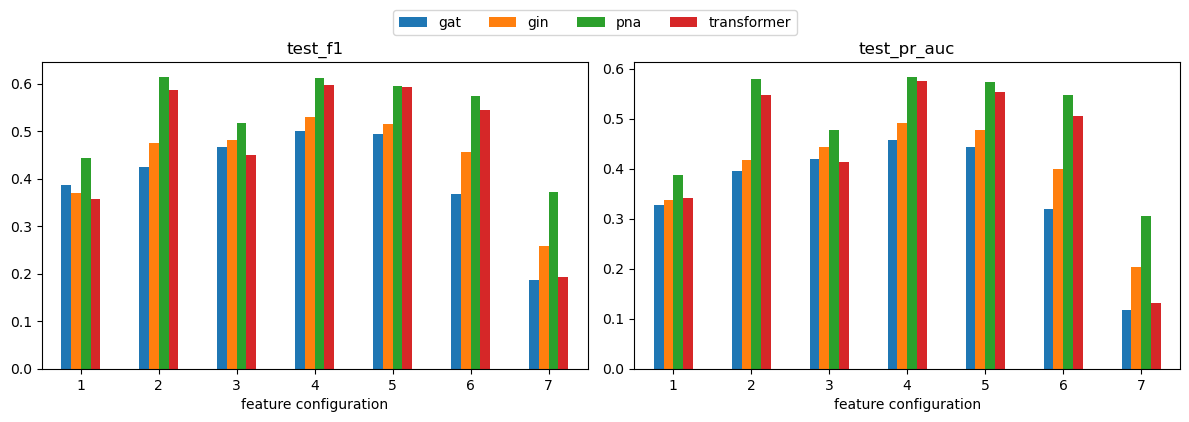

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric in zip(axes, ['test_f1', 'test_pr_auc']):
    df.groupby(['config', 'model'])[metric].mean().unstack('model').plot.bar(ax=axis, rot=0, legend=False)
    axis.set_title(metric); axis.set_xlabel('feature configuration')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=df.model.nunique(), bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()

## Training curves of one run

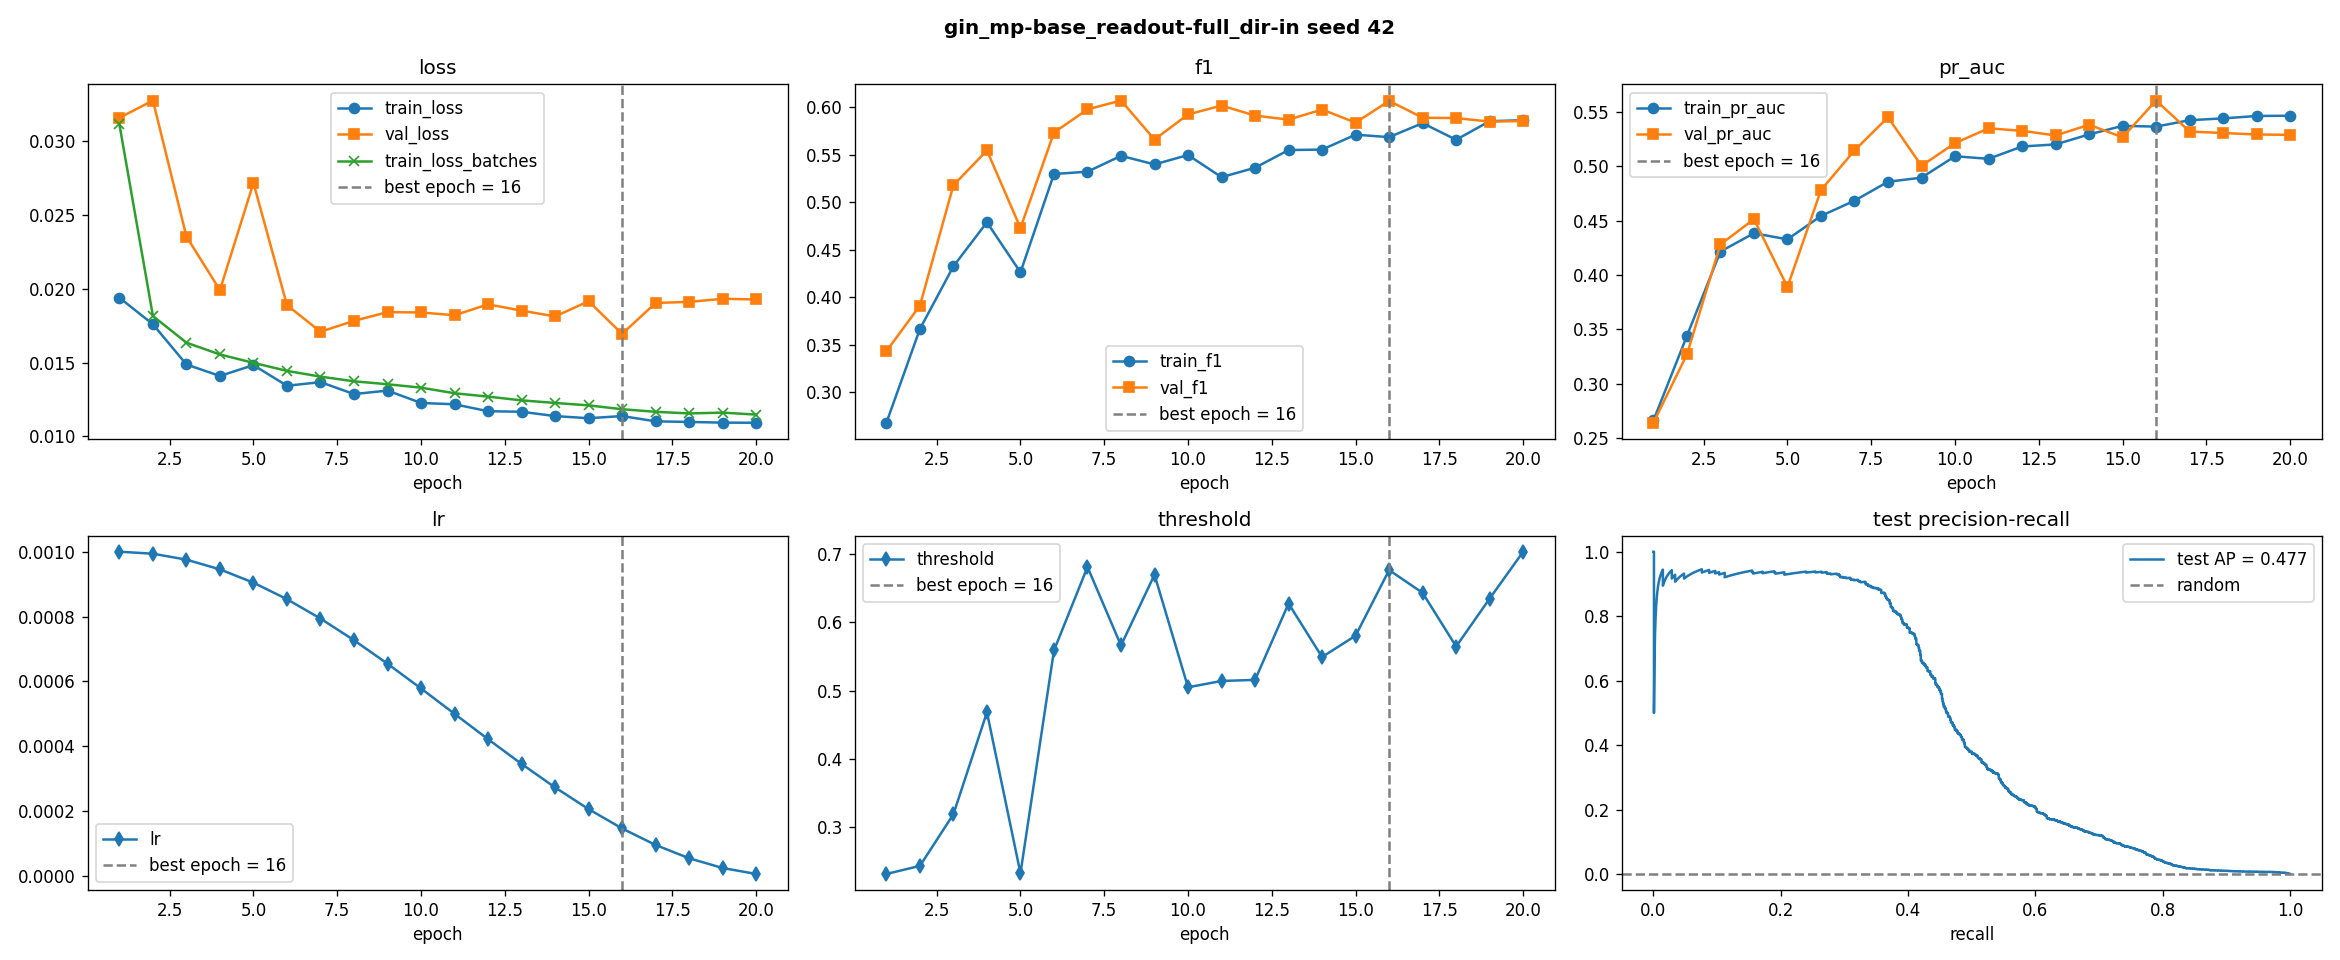

In [4]:
MODEL, CONFIG, SEED = 'gin', 5, 42
run = df[(df.model == MODEL) & (df.config == CONFIG)].iloc[0]
display(Image(f"{ROOT}/outputs/train/{MODEL}/{MODEL}_mp-{run.mp}_readout-{run.readout}_dir-in/seed-{SEED}/curves.png"))